<a href="https://colab.research.google.com/github/24sahil25-source/BA305-BoardGameGeek-Fall2026/blob/main/notebooks/13_final_comparison_ansel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 10: compare the tree, k-NN and the neural network on the final rows, choose one to deploy, show what drives it, and hand it to task 3

Tasks 1 and 2 are in. Notebook 05 settled the rows, the split, the inputs and the imputer, and tuned the tree and k-NN. Notebook 06 tuned a neural network on the same rows. Notebook 08 (task 4) decided that year of publication stays an input. This notebook puts the three methods side by side on one footing and answers four questions:

1. How do the tree, k-NN and the network compare on the same rows, split, folds and score?
2. Which one would we deploy, and why?
3. What drives that model?
4. What does task 3's cost-based decision look like with that model, and what does notebook 07 need to paste in to re-run on it?

Every choice below was made by Ansel Weng before any code was written:

| # | Decision | Choice |
| --- | --- | --- |
| 1 | Rows, split, inputs, imputer | Notebook 05's section 13 cell, pasted unchanged: 21,379 games, 14,964 training and 6,415 test, 45 inputs, `SimpleImputer(strategy="median")` as the first step of every pipeline |
| 2 | Settings | Not re-tuned. Tree `max_depth=12, min_samples_leaf=50` (notebook 05); k-NN `n_neighbors=30, weights="distance", p=1` with `StandardScaler` (notebook 05); network `(2, 2, 2)`, logistic, `lbfgs`, `tol=1e-8`, `max_iter=2000`, `MinMaxScaler`, rating scaled to 0–1 by `(rating - 1) / 9` (notebook 06) |
| 3 | Cross-validation | All three re-scored on the same `KFold(n_splits=5, shuffle=True, random_state=0)` used in 05 and 06, so their numbers sit on one footing |
| 4 | Network seeds | Seeds 1 to 5, as in notebook 06. In the deploy rule the network is represented by the **CV RMSE of the 5-seed average**, the form it would be deployed in, so the rule scores exactly what would be used. Notebook 06's number (the mean over seeds of each seed's CV RMSE) is shown alongside. *Changed by Ansel Weng after the first run*: that run used notebook 06's number, which put the network 0.0049 ahead of the tree, inside the margin, so the tree was deployed. See section 11 |
| 5 | Deploy rule | Lowest CV RMSE on the training folds. Any model within **0.005 RMSE** of the best counts as tied, and the **simplest tied model wins**: tree < k-NN < network. This is notebook 05's tie rule. The test rows are reported, never used to choose |
| 6 | Deployed network, if it wins | The average of the 5 seeds' predictions, so no single lucky (or stuck) seed decides it |
| 7 | References | `DummyRegressor` (ground rule 3) and linear regression (notebook 06's reference) |
| 8 | Test sets | All 6,415 test games (headline), the 5,395 complete games (notebook 04's test rows) and the 1,020 games with a missing input, as in notebook 05 |
| 9 | What drives the model | Permutation importance on the test rows for all three models, so they are compared on one footing; the tree's own `feature_importances_` if the tree is deployed (Session 19's method); and predicted against actual rating across the top inputs |
| 10 | Task 3 | Notebook 07 belongs to Andrew (ground rule 6), so it is not edited here. Section 9 re-runs task 3's cutoff and cost steps on the deployed model as a check, and section 10 gives the cell that notebook 07 pastes in |

Ground rules: same loading cell as notebooks 02 to 06; RMSE with MAE and R² next to `DummyRegressor`; no post-release column (`rank`, `bayes_average`, `users_rated`, `owned`, `trading`, `wanting`, `wishing`) as an input; every imputer and scaler fitted on training rows only, inside a `Pipeline`; the test rows scored once.

In [1]:
# --- Ansel Weng: task 10, compare the tree, k-NN and the neural network on the final rows, choose one to deploy, show what drives it, and hand it to task 3 ---
# [AI-assisted] Claude Code, 2026-11-11. Every code and markdown cell in this notebook was generated with Claude Code from Ansel Weng's decisions, notebooks 05 to 08 and the course labs; reviewed and edited by Ansel Weng.
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, precision_score, recall_score
from sklearn.exceptions import ConvergenceWarning

warnings.simplefilter("ignore", ConvergenceWarning)  # the network's solver warns when it hits max_iter; we count those fits ourselves, as notebook 06 does

## 1. Load the data, and rebuild task 1's rows, split and inputs

In [2]:
# [AI-assisted] Claude Code, 2026-11-11. Same loading cell as notebooks 02 to 06, and the figure folder helper from notebook 05; reviewed and edited by Ansel Weng.
BASE = "https://raw.githubusercontent.com/24sahil25-source/BA305-BoardGameGeek-Fall2026/main/data/"
games = pd.read_csv(BASE + "bgg_clean.csv")
print(games.shape)

FIG_DIR = "../figures" if os.path.isdir("../figures") else "."

def save(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=200, bbox_inches="tight")

(21631, 24)


**Task 1's cell, pasted unchanged** from notebook 05, section 13. Notebook 06 pasted the same cell, so the three models see exactly the same 14,964 training and 6,415 test games and the same 45 inputs. The checks after the paste confirm the counts and that none of the post-release columns is an input.

In [3]:
# [AI-assisted] Claude Code, 2026-11-11. Notebook 05's section 13 cell (rows, split and inputs), pasted unchanged, followed by checks; reviewed and edited by Ansel Weng.
# ---- paste from here: rows, split, inputs and imputer as settled by task 1 (notebooks/05_imputation_tuning_ansel.ipynb) ----
numeric_cols = ["yearpublished", "minplayers", "maxplayers", "minplaytime", "maxplaytime", "minage", "n_mechanics", "n_categories"]
gaps = games[numeric_cols].isna().sum(axis=1)
data = games[games["yearpublished"].notna() & (gaps < 4)].copy()           # drop no-year games and games missing 4+ of the 8 inputs
data["complete"] = data[numeric_cols].notna().all(axis=1)
tr_c, te_c = train_test_split(data[data["complete"]].reset_index(drop=True), test_size=0.3, random_state=1)    # = notebook 04's split
tr_i, te_i = train_test_split(data[~data["complete"]].reset_index(drop=True), test_size=0.3, random_state=1)
train_df, test_df = pd.concat([tr_c, tr_i], ignore_index=True), pd.concat([te_c, te_i], ignore_index=True)
y_train, y_test = train_df["average"], test_df["average"]

def build_inputs(frame, mechanics, categories):
    X = frame[numeric_cols].copy()
    for col in ["minplayers", "maxplayers", "minplaytime", "maxplaytime"]:
        X[col] = np.log10(X[col])
    mech = frame["boardgamemechanic"].str.get_dummies(sep="|").reindex(columns=mechanics, fill_value=0).add_prefix("mech_")
    cat = frame["boardgamecategory"].str.get_dummies(sep="|").reindex(columns=categories, fill_value=0).add_prefix("cat_")
    flags = pd.DataFrame({"mech_list_missing": frame["boardgamemechanic"].isna().astype(int),
                          "cat_list_missing": frame["boardgamecategory"].isna().astype(int)}, index=frame.index)
    return pd.concat([X, mech, cat, flags], axis=1)

top_mech = train_df["boardgamemechanic"].str.get_dummies(sep="|").mean().sort_values(ascending=False).head(20).index
top_cat = train_df["boardgamecategory"].str.get_dummies(sep="|").mean().sort_values(ascending=False).head(15).index
X_train, X_test = build_inputs(train_df, top_mech, top_cat), build_inputs(test_df, top_mech, top_cat)
# ---- paste to here ----

test_complete = test_df["complete"].values
post_release = ["rank", "bayes_average", "users_rated", "owned", "trading", "wanting", "wishing"]
assert (len(X_train), len(X_test), X_train.shape[1]) == (14964, 6415, 45), "rows or inputs differ from notebooks 05 and 06"
assert not set(post_release) & set(X_train.columns)
print("training games:", len(X_train), "| test games:", len(X_test), f"({test_complete.sum():,} complete, {(~test_complete).sum():,} with a gap) | inputs:", X_train.shape[1])
print("post-release columns among the inputs:", [c for c in post_release if c in X_train.columns])

training games: 14964 | test games: 6415 (5,395 complete, 1,020 with a gap) | inputs: 45
post-release columns among the inputs: []


## 2. The three models, at the settings notebooks 05 and 06 chose

Decision 2: nothing is re-tuned. Each model is a `Pipeline` that starts with task 1's median imputer, so in every cross-validation fold the imputer and scaler are fitted on the four training folds only.

- **Tree and k-NN** are notebook 05's pipelines, built the same way (`imputer_steps` + `model_steps` in notebook 05).
- **The network** is notebook 06's pipeline: median imputer, `MinMaxScaler`, then `MLPRegressor`. Notebook 06 scaled the rating to 0–1 with `to_scaled` and converted predictions back with `to_ratings`. Here the same two functions are handed to scikit-learn's `TransformedTargetRegressor`, which applies them around `fit` and `predict`. The arithmetic is identical; the only difference is that the network can then be scored, cross-validated and permuted with the same code as the tree and k-NN.
- **`SeedAverage`** fits the network once per seed (1 to 5) and averages the five predictions. It is the deployed form of the network if the network wins (decision 6).

In [4]:
# [AI-assisted] Claude Code, 2026-11-11. The three tuned pipelines, the two references and the 5-seed network average; reviewed and edited by Ansel Weng.
SEEDS = [1, 2, 3, 4, 5]
MAX_ITER = 2000

def to_scaled(ratings):          # notebook 06's rating scaling: the 1-10 scale's own limits, nothing learned from the data
    return (np.asarray(ratings) - 1) / 9

def to_ratings(scaled):          # notebook 06's inverse, the lab's to_euros adapted to ratings
    return np.asarray(scaled) * 9 + 1

def make_tree():                 # notebook 05, section 7: depth 12, at least 50 games per leaf
    return Pipeline([("impute", SimpleImputer(strategy="median")),
                     ("model", DecisionTreeRegressor(max_depth=12, min_samples_leaf=50, random_state=0))])

def make_knn():                  # notebook 05, section 8: k = 30, distance weights, Manhattan distance
    return Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()),
                     ("model", KNeighborsRegressor(n_neighbors=30, weights="distance", p=1))])

def make_network(seed):          # notebook 06, Part 4: (2, 2, 2) logistic, lbfgs, the lab's tol and max_iter fix
    net = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", MinMaxScaler()),
                    ("model", MLPRegressor(hidden_layer_sizes=(2, 2, 2), activation="logistic", solver="lbfgs",
                                           tol=1e-8, max_iter=MAX_ITER, random_state=seed))])
    return TransformedTargetRegressor(regressor=net, func=to_scaled, inverse_func=to_ratings, check_inverse=False)

class SeedAverage(RegressorMixin, BaseEstimator):
    """The network fitted once per seed; predicts the average of the seeds' predictions."""
    def __init__(self, seeds=(1, 2, 3, 4, 5)):
        self.seeds = seeds

    def fit(self, X, y):
        self.networks_ = [make_network(seed).fit(X, y) for seed in self.seeds]
        return self

    def predict(self, X):
        return np.mean([net.predict(X) for net in self.networks_], axis=0)

def make_reference(name):
    model = DummyRegressor(strategy="mean") if name == "baseline" else LinearRegression()
    return Pipeline([("impute", SimpleImputer(strategy="median")), ("model", model)])

MODELS = ["tree", "k-NN", "network"]                       # simplest first: the order decision 5 breaks ties by
make = {"tree": make_tree, "k-NN": make_knn}

## 3. Cross-validated RMSE on the same folds

Every model is scored on the same 5 folds of the 14,964 training games. The network is cross-validated once per seed. As in notebooks 05 and 06, the CV RMSE is the mean of the five fold RMSEs.

In [5]:
# [AI-assisted] Claude Code, 2026-11-11. 5-fold cross-validated RMSE for the references, the tree, k-NN and the network with each seed; reviewed and edited by Ansel Weng.
folds = KFold(n_splits=5, shuffle=True, random_state=0)

def cv_rmse(model):
    return -cross_val_score(model, X_train, y_train, cv=folds, scoring="neg_root_mean_squared_error", n_jobs=-1)

start = time.time()
cv_folds = {name: cv_rmse(make_reference(name)) for name in ["baseline", "linear regression"]}
cv_folds["tree"] = cv_rmse(make_tree())
cv_folds["k-NN"] = cv_rmse(make_knn())
network_cv = pd.DataFrame({seed: cv_rmse(make_network(seed)) for seed in SEEDS})      # rows: folds, columns: seeds
network_cv.index = [f"fold {i + 1}" for i in range(5)]
print(f"cross-validation took {time.time() - start:.0f} seconds")
network_cv.round(4).assign(**{"mean over seeds": network_cv.mean(axis=1)}).T.assign(**{"CV RMSE": lambda d: d.mean(axis=1)}).round(4)

cross-validation took 49 seconds


,fold 1,fold 2,fold 3,fold 4,fold 5,CV RMSE
1,0.6944,0.7115,0.6766,0.6957,0.6989,0.6954
2,0.6946,0.6952,0.6664,0.6942,0.6886,0.6878
3,0.7331,0.7441,0.6724,0.6970,0.6969,0.7087
4,0.6931,0.7005,0.6690,0.6866,0.6837,0.6866
5,0.6838,0.7062,0.6692,0.6906,0.6798,0.6859
mean over seeds,0.6998,0.7115,0.6707,0.6928,0.6896,0.6929


In [6]:
# [AI-assisted] Claude Code, 2026-11-11. CV RMSE of the 5-seed average, the form the network would be deployed in; this is the network's score in the deploy rule (decision 4); reviewed and edited by Ansel Weng.
start = time.time()
seed_average_cv = cv_rmse(SeedAverage(seeds=SEEDS))
print(f"5-seed average of the network: CV RMSE {seed_average_cv.mean():.4f} (sd over folds {seed_average_cv.std():.4f}), {time.time() - start:.0f} seconds")

5-seed average of the network: CV RMSE 0.6826 (sd over folds 0.0110), 47 seconds


In [7]:
# [AI-assisted] Claude Code, 2026-11-11. One cross-validation table for every model; reviewed and edited by Ansel Weng.
per_seed = network_cv.mean(axis=0)              # each seed's CV RMSE
cv_table = pd.DataFrame({name: {"CV RMSE": s.mean(), "sd over folds": s.std(), "sd over seeds": np.nan} for name, s in cv_folds.items()}).T
cv_table.loc["network"] = {"CV RMSE": seed_average_cv.mean(), "sd over folds": seed_average_cv.std(), "sd over seeds": np.nan}   # the 5-seed average: used by the deploy rule
cv_table.loc["network, mean of single seeds (notebook 06)"] = {"CV RMSE": per_seed.mean(), "sd over folds": network_cv.mean(axis=1).std(), "sd over seeds": per_seed.std()}
cv_table["notebook 05 or 06 reported"] = pd.Series({"tree": 0.6977, "k-NN": 0.7277, "network, mean of single seeds (notebook 06)": 0.6929, "baseline": 0.9222, "linear regression": 0.7457})
cv_table.round(4)

,CV RMSE,sd over folds,sd over seeds,notebook 05 or 06 reported
baseline,0.9222,0.0115,NaN,0.9222
linear regression,0.7457,0.0074,NaN,0.7457
tree,0.6977,0.0094,NaN,0.6977
k-NN,0.7277,0.0077,NaN,0.7277
network,0.6826,0.0110,NaN,NaN
"network, mean of single seeds (notebook 06)",0.6929,0.0150,0.0096,0.6929


## 4. Which model to deploy

Decision 5 applied: the best CV RMSE among the three methods, a 0.005 margin, and the simplest tied model wins.

In [8]:
# [AI-assisted] Claude Code, 2026-11-11. Decision 5 applied: tied = within 0.005 of the best CV RMSE; the simplest tied model is deployed; reviewed and edited by Ansel Weng.
MARGIN = 0.005
method_cv = cv_table.loc[MODELS, "CV RMSE"]
gap = method_cv - method_cv.min()
tied = gap <= MARGIN
DEPLOY = next(name for name in MODELS if tied[name])
display(pd.DataFrame({"CV RMSE": method_cv, "gap to best": gap, "tied with best": tied}).round(4))
print("best CV RMSE:", method_cv.idxmin(), f"({method_cv.min():.4f})")
print("tied with it:", list(tied[tied].index))
print("deployed (simplest tied model):", DEPLOY)

,CV RMSE,gap to best,tied with best
tree,0.6977,0.0152,False
k-NN,0.7277,0.0451,False
network,0.6826,0.0000,True


best CV RMSE: network (0.6826)
tied with it: ['network']
deployed (simplest tied model): network


**Takeaway: the network, as the average of five seeds, is deployed.** The re-run cross-validation reproduces notebooks 05 and 06 to the fourth decimal: tree 0.6977, k-NN 0.7277, and 0.6929 for notebook 06's mean over single seeds. Scored in the form it would be deployed in (decision 4), the 5-seed average reaches **0.6826**. That is 0.015 better than the tree, three times decision 5's 0.005 margin, so nothing is tied and the network wins outright. k-NN is 0.045 behind.

**How the decision changed.** The first run of this notebook scored the network by notebook 06's single-seed mean (0.6929). That put it only 0.0049 ahead of the tree, just inside the margin, and the tree was deployed as the simpler tied model. Ansel Weng then changed decision 4 so the rule scores what would actually be used. The gap of 0.015 is also larger than the fold-to-fold spread of either model (0.009 to 0.011). Averaging the seeds removes most of the network's seed-to-seed noise, which was the reason it looked tied before.

**What the choice costs.** The network is five fitted models instead of one, takes 1 to 3 minutes to fit instead of a second, and has no rules a producer can read. Sections 7 and 8 explain what drives it instead.

## 5. Score the test rows once

Each model is fitted on all 14,964 training games and scored once on the test games. The network is fitted with each seed (reported as mean and spread, as notebook 06 does) and as the 5-seed average (the form it would be deployed in).

In [9]:
# [AI-assisted] Claude Code, 2026-11-11. Fit every model on the training games and score each test set once; reviewed and edited by Ansel Weng.
def metrics(y, pred):
    return {"games": len(y), "RMSE": np.sqrt(mean_squared_error(y, pred)), "MAE": mean_absolute_error(y, pred), "R2": r2_score(y, pred)}

start = time.time()
fitted = {"baseline": make_reference("baseline").fit(X_train, y_train),
          "linear regression": make_reference("linear regression").fit(X_train, y_train),
          "tree": make_tree().fit(X_train, y_train),
          "k-NN": make_knn().fit(X_train, y_train),
          "network, 5-seed average": SeedAverage(seeds=SEEDS).fit(X_train, y_train)}
seed_nets = dict(zip(SEEDS, fitted["network, 5-seed average"].networks_))   # the five single-seed networks inside the average
print(f"fitting took {time.time() - start:.0f} seconds")

steps = {seed: net.regressor_.named_steps["model"].n_iter_ for seed, net in seed_nets.items()}
print("network training steps per seed:", steps, "| hit max_iter:", [s for s, n in steps.items() if n >= MAX_ITER])

test_sets = {"all test games": np.ones(len(y_test), dtype=bool), "complete test games": test_complete,
             "test games with a missing input": ~test_complete}
test_pred = {name: model.predict(X_test) for name, model in fitted.items()}
seed_pred = {seed: net.predict(X_test) for seed, net in seed_nets.items()}

rows = []
for set_name, mask in test_sets.items():
    for name, pred in test_pred.items():
        rows.append({"test set": set_name, "model": name, **metrics(y_test[mask], pred[mask])})
    per_seed_scores = pd.DataFrame([metrics(y_test[mask], p[mask]) for p in seed_pred.values()])
    rows.append({"test set": set_name, "model": "network, mean of 5 seeds", **per_seed_scores.mean().to_dict()})
    rows.append({"test set": set_name, "model": "network, sd over 5 seeds", **per_seed_scores.std().drop("games").to_dict()})
order = ["baseline", "linear regression", "tree", "k-NN", "network, mean of 5 seeds", "network, sd over 5 seeds", "network, 5-seed average"]
final = pd.DataFrame(rows).set_index(["test set", "model"]).reindex(pd.MultiIndex.from_product([list(test_sets), order]))
final["games"] = final["games"].astype("Int64")
final.round(3)

fitting took 155 seconds
network training steps per seed: {1: 1742, 2: 1591, 3: 2000, 4: 1329, 5: 886} | hit max_iter: [3]


games   RMSE    MAE  \
all test games                  baseline                   6415  0.927  0.728   
                                linear regression          6415  0.748  0.576   
                                tree                       6415  0.702  0.532   
                                k-NN                       6415  0.730  0.556   
                                network, mean of 5 seeds   6415  0.700  0.529   
                                network, sd over 5 seeds   <NA>  0.005  0.004   
                                network, 5-seed average    6415  0.692  0.522   
complete test games             baseline                   5395  0.904  0.712   
                                linear regression          5395  0.731  0.562   
                                tree                       5395  0.682  0.520   
                                k-NN                       5395  0.719  0.547   
                                network, mean of 5 seeds   5395  0.681  0.516   
                                network, sd over 5 seeds   <NA>  0.005  0.003   
                                network, 5-seed average    5395  0.672  0.509   
test games with a missing input baseline                   1020  1.037  0.810   
                                linear regression          1020  0.835  0.646   
                                tree                       1020  0.796  0.596   
                                k-NN                       1020  0.789  0.605   
                                network, mean of 5 seeds   1020  0.793  0.598   
                                network, sd over 5 seeds   <NA>  0.005  0.006   
                                network, 5-seed average    1020  0.786  0.592   

                                                             R2  
all test games                  baseline                 -0.000  
                                linear regression         0.348  
                                tree                      0.427  
                                k-NN                      0.379  
                                network, mean of 5 seeds  0.430  
                                network, sd over 5 seeds  0.008  
                                network, 5-seed average   0.443  
complete test games             baseline                 -0.004  
                                linear regression         0.345  
                                tree                      0.429  
                                k-NN                      0.366  
                                network, mean of 5 seeds  0.431  
                                network, sd over 5 seeds  0.008  
                                network, 5-seed average   0.445  
test games with a missing input baseline                 -0.058  
                                linear regression         0.313  
                                tree                      0.376  
                                k-NN                      0.386  
                                network, mean of 5 seeds  0.381  
                                network, sd over 5 seeds  0.008  
                                network, 5-seed average   0.393

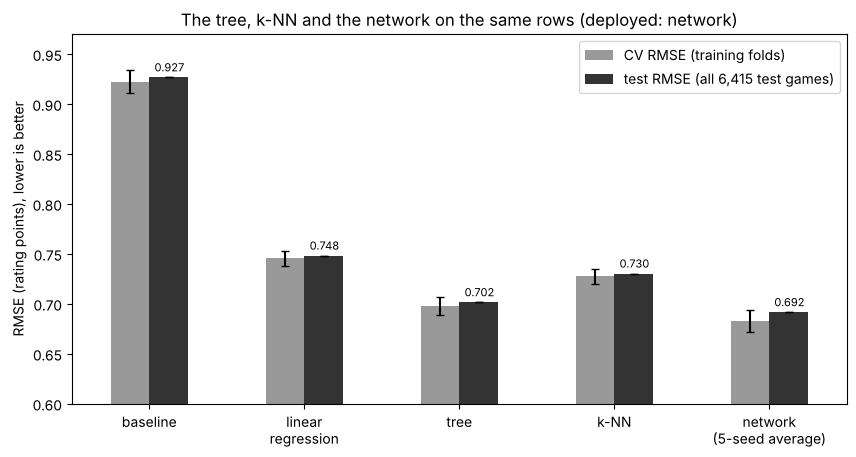

Error bars: sd over the 5 folds. The test bars are single scores; section 5's table gives the network's spread over seeds.


In [10]:
# [AI-assisted] Claude Code, 2026-11-11. Chart: CV RMSE with fold spread next to test RMSE, every model; reviewed and edited by Ansel Weng.
chart = pd.DataFrame({
    "CV RMSE (training folds)": [cv_table.loc[n, "CV RMSE"] for n in ["baseline", "linear regression", "tree", "k-NN", "network"]],
    "test RMSE (all 6,415 test games)": [final.loc[("all test games", n), "RMSE"] for n in ["baseline", "linear regression", "tree", "k-NN", "network, 5-seed average"]],
}, index=["baseline", "linear\nregression", "tree", "k-NN", "network\n(5-seed average)"])
errors = pd.DataFrame({
    "CV RMSE (training folds)": [cv_table.loc[n, "sd over folds"] for n in ["baseline", "linear regression", "tree", "k-NN", "network"]],
    "test RMSE (all 6,415 test games)": [0, 0, 0, 0, 0],
}, index=chart.index)
ax = chart.plot(kind="bar", yerr=errors, capsize=3, rot=0, figsize=(10, 4.8), color=["0.6", "0.2"])
ax.set_ylim(0.6, 0.97)
ax.set_title(f"The tree, k-NN and the network on the same rows (deployed: {DEPLOY})")
ax.set_xlabel("")
ax.set_ylabel("RMSE (rating points), lower is better")
ax.legend(loc="upper right")
for i, v in enumerate(chart.iloc[:, 1]):
    ax.text(i + 0.13, v + 0.006, f"{v:.3f}", ha="center", fontsize=8)
save("13_model_comparison.png")
plt.show()
print("Error bars: sd over the 5 folds. The test bars are single scores; section 5's table gives the network's spread over seeds.")

**Takeaway: the test rows confirm the choice.** On all 6,415 test games, the deployed network (5-seed average) scores **RMSE 0.692, MAE 0.522, R² 0.443**. The tree scores 0.702, 0.532 and 0.427, k-NN 0.730, 0.556 and 0.379, linear regression 0.748, and the baseline 0.927. A single-seed network scores 0.700 ± 0.005 (mean ± sd over five seeds), so averaging the seeds is worth about 0.008 on the test games. The tree, k-NN and single-seed rows match notebooks 05 and 06 exactly.

The order holds on the 5,395 complete games (network 0.672, tree 0.682, k-NN 0.719). On the 1,020 games with a missing input, everything is worse (baseline 1.037). The network is still best there (0.786), but the three models are within 0.01 of each other.

### Diagnosing the fit

Training RMSE (each model scored on the games it was fitted on) against CV RMSE and test RMSE. A training error far below the other two is the overfitting signal. k-NN with distance weights scores each training game against itself (notebook 05, section 8b), so its training RMSE is near zero by construction and says nothing about fit.

In [11]:
# [AI-assisted] Claude Code, 2026-11-11. Training, CV and test RMSE side by side for every model; reviewed and edited by Ansel Weng.
fit_rows = []
for name, cv_name, test_name in [("linear regression", "linear regression", "linear regression"), ("tree", "tree", "tree"),
                                 ("k-NN", "k-NN", "k-NN"), ("network, 5-seed average", "network", "network, 5-seed average")]:
    train_rmse = np.sqrt(mean_squared_error(y_train, fitted[name].predict(X_train)))
    fit_rows.append({"model": name, "training RMSE": train_rmse, "CV RMSE": cv_table.loc[cv_name, "CV RMSE"],
                     "test RMSE": final.loc[("all test games", test_name), "RMSE"]})
fit_table = pd.DataFrame(fit_rows).set_index("model")
fit_table["test - training"] = fit_table["test RMSE"] - fit_table["training RMSE"]
fit_table.round(3)

,training RMSE,CV RMSE,test RMSE,test - training
model,,,,
linear regression,0.743,0.746,0.748,0.005
tree,0.665,0.698,0.702,0.037
k-NN,0.033,0.728,0.730,0.697
"network, 5-seed average",0.678,0.683,0.692,0.014


**Takeaway: none of the three overfits badly.** The deployed network's training RMSE (0.678) is close to its CV (0.683) and test (0.692) RMSE, a gap of 0.014. It fits new games about as well as the games it learned from. The tree's gap is 0.037, held down by the 50-games-per-leaf limit (notebook 05, section 7b). k-NN's near-zero training RMSE (0.033) is the distance-weighting artefact noted above, not overfitting; its CV and test RMSE agree (0.728 and 0.730). The models are limited by what the inputs can say about a game, not by memorising the training games.

## 6. Where the three models agree and disagree

Predicted against actual rating on the test games, one panel per model, and the correlation between the models' predictions. If the models make the same mistakes, the choice between them matters less than the inputs they share.

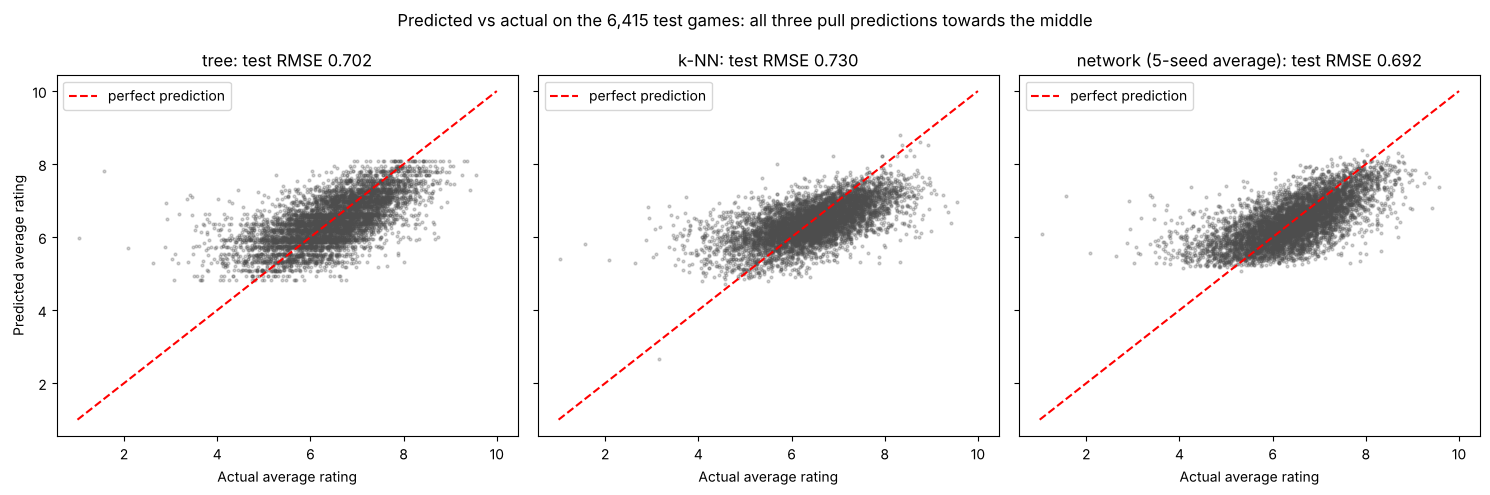

correlation between the models' test predictions:


,tree,k-NN,network (5-seed average)
tree,1.000,0.756,0.902
k-NN,0.756,1.000,0.811
network (5-seed average),0.902,0.811,1.000


In [12]:
# [AI-assisted] Claude Code, 2026-11-11. Predicted vs actual for each model, and how closely their predictions agree; reviewed and edited by Ansel Weng.
panels = [("tree", "tree"), ("k-NN", "k-NN"), ("network, 5-seed average", "network (5-seed average)")]
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
for ax, (name, label) in zip(axes, panels):
    ax.scatter(y_test, test_pred[name], s=4, alpha=0.25, color="0.3")
    ax.plot([1, 10], [1, 10], color="red", linestyle="--", label="perfect prediction")
    ax.set_title(f"{label}: test RMSE {final.loc[('all test games', name), 'RMSE']:.3f}")
    ax.set_xlabel("Actual average rating")
    ax.legend(loc="upper left")
axes[0].set_ylabel("Predicted average rating")
fig.suptitle(f"Predicted vs actual on the {len(y_test):,} test games: all three pull predictions towards the middle")
plt.tight_layout()
save("13_predicted_vs_actual.png")
plt.show()

agree = pd.DataFrame({label: test_pred[name] for name, label in panels})
print("correlation between the models' test predictions:")
agree.corr().round(3)

**Takeaway: the three models make largely the same predictions, and the same mistakes.** The tree's and the network's test predictions correlate at 0.90. k-NN, which measures similarity across all 45 inputs at once, is the most different (0.76 with the tree). All three compress the rating scale: low-rated games are predicted too high and high-rated games too low, the pattern notebook 07 found. The deployed network is the best of the three, but only by 0.01 RMSE. What would help more is new information about a game, such as a designer's or publisher's track record (notebook 07's suggested next step).

## 7. What drives the models

**Permutation importance** (decision 9): shuffle one input's values across the test games, so it carries no information, and measure how much the test RMSE rises. A large rise means the model relies on that input. It treats every model the same way, which the tree's built-in importance cannot do, and it is measured on games the models never saw. Each input is shuffled 10 times; the bars show the mean rise and the error bars its spread.

In [13]:
# [AI-assisted] Claude Code, 2026-11-11. Permutation importance on the test games for the tree, k-NN and the network; reviewed and edited by Ansel Weng.
start = time.time()
perm = {}
for name, label in panels:
    result = permutation_importance(fitted[name], X_test, y_test, scoring="neg_root_mean_squared_error",
                                    n_repeats=10, random_state=0, n_jobs=-1)
    perm[label] = pd.DataFrame({"rise in RMSE": result.importances_mean, "sd": result.importances_std}, index=X_test.columns)
print(f"permutation importance took {time.time() - start:.0f} seconds")

deployed_label = dict(panels)[{"tree": "tree", "k-NN": "k-NN", "network": "network, 5-seed average"}[DEPLOY]]
rank_order = perm[deployed_label]["rise in RMSE"].sort_values(ascending=False).index
perm_table = pd.DataFrame({label: p["rise in RMSE"] for label, p in perm.items()}).loc[rank_order]
perm_table.head(12).round(3)

permutation importance took 316 seconds


,tree,k-NN,network (5-seed average)
yearpublished,0.209,0.018,0.162
maxplaytime,0.055,0.015,0.060
n_mechanics,0.051,0.013,0.051
mech_Roll / Spin and Move,0.029,0.022,0.030
mech_list_missing,0.006,0.014,0.019
cat_Wargame,0.040,0.004,0.016
maxplayers,0.022,0.008,0.007
cat_Humor,0.000,0.001,0.003
mech_Area Movement,0.001,0.002,0.003
minage,0.012,0.014,0.003


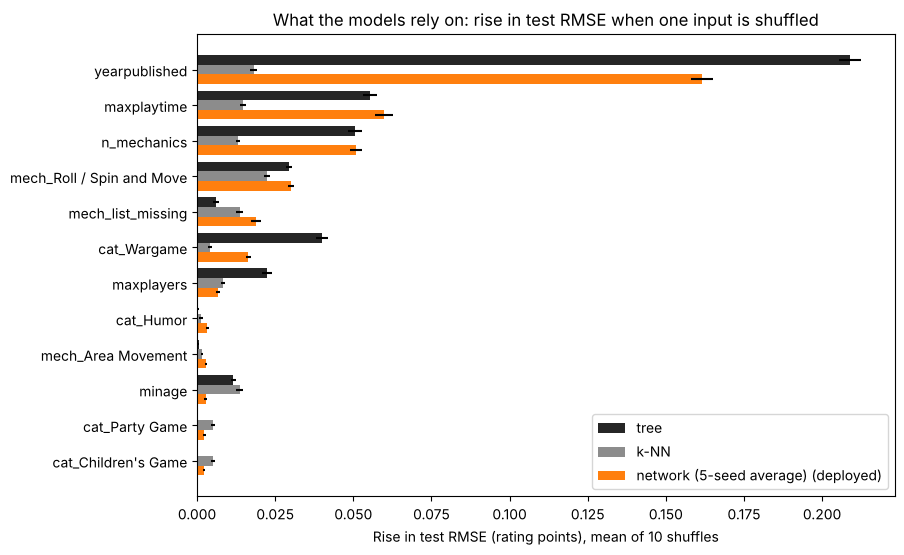

In [14]:
# [AI-assisted] Claude Code, 2026-11-11. Chart: the 12 inputs the deployed model relies on most, with the other two models alongside; reviewed and edited by Ansel Weng.
top = list(rank_order[:12])
fig, ax = plt.subplots(figsize=(9, 6))
height = 0.27
colours = {"tree": "0.15", "k-NN": "0.55", "network (5-seed average)": "tab:orange"}
for j, label in enumerate(perm):
    ax.barh(np.arange(len(top)) + (j - 1) * height, perm[label].loc[top, "rise in RMSE"], height=height,
            xerr=perm[label].loc[top, "sd"], color=colours[label], label=label + (" (deployed)" if label == deployed_label else ""))
ax.set_yticks(np.arange(len(top)))
ax.set_yticklabels(top)
ax.invert_yaxis()
ax.set_title("What the models rely on: rise in test RMSE when one input is shuffled")
ax.set_xlabel("Rise in test RMSE (rating points), mean of 10 shuffles")
ax.legend(loc="lower right")
save("13_permutation_importance.png")
plt.show()

In [15]:
# [AI-assisted] Claude Code, 2026-11-11. The tree's own feature importance, Session 19's method, next to its permutation importance; reviewed and edited by Ansel Weng.
tree_importance = pd.Series(fitted["tree"].named_steps["model"].feature_importances_, index=X_train.columns)
both = pd.DataFrame({"built-in importance (share of squared-error reduction, training games)": tree_importance,
                     "permutation importance (rise in test RMSE)": perm["tree"]["rise in RMSE"]})
both = both.sort_values(both.columns[0], ascending=False)
if DEPLOY == "tree":
    ax = tree_importance.sort_values().tail(12).plot.barh(color="0.4", figsize=(8, 5))
    ax.set_title("Deployed tree: 12 most used inputs (built-in importance)")
    ax.set_xlabel("Share of squared-error reduction")
    save("13_tree_feature_importance.png")
    plt.show()
both.head(12).round(3)

,"built-in importance (share of squared-error reduction, training games)",permutation importance (rise in test RMSE)
yearpublished,0.405,0.209
cat_Wargame,0.158,0.040
maxplaytime,0.126,0.055
n_mechanics,0.114,0.051
mech_Roll / Spin and Move,0.069,0.029
maxplayers,0.036,0.022
minage,0.026,0.012
minplaytime,0.018,0.017
mech_list_missing,0.014,0.006
cat_Abstract Strategy,0.005,0.000


**Takeaway: the deployed network is driven by year of publication, then play time and the number of mechanics.** Shuffling `yearpublished` raises the network's test RMSE by 0.162, almost three times more than any other input. Next come maximum play time (0.060), the number of mechanics (0.051), the Roll / Spin and Move mechanic (0.030, which lowers the rating: it marks old roll-and-move family games) and `mech_list_missing` (0.019). The wargame category follows (0.016). Every other input adds less than 0.01. The tree relies on the same top inputs in nearly the same order (year 0.209, play time 0.055, mechanics 0.051), so the story does not depend on which of the two is deployed. k-NN spreads its reliance thinly (no input above 0.022), because its distances use every input at once.

Two differences from the tree: the network leans less on the wargame category (0.016 against 0.040) and minimum age (0.003 against 0.012). The tree's built-in importance (Session 19's method, shown in the table for comparison) names the same top five as permutation. The network has no built-in importance, which is why decision 9 put all three models on permutation importance.

### What the top inputs do to the prediction

Importance says *how much* the deployed model relies on an input, not *in which direction*. As in Session 19's notebook, the test games are grouped by each of the three most important inputs, and the average predicted rating is set against the average actual rating in each group. Play times and player counts are shown in their original units (the model sees their log10).

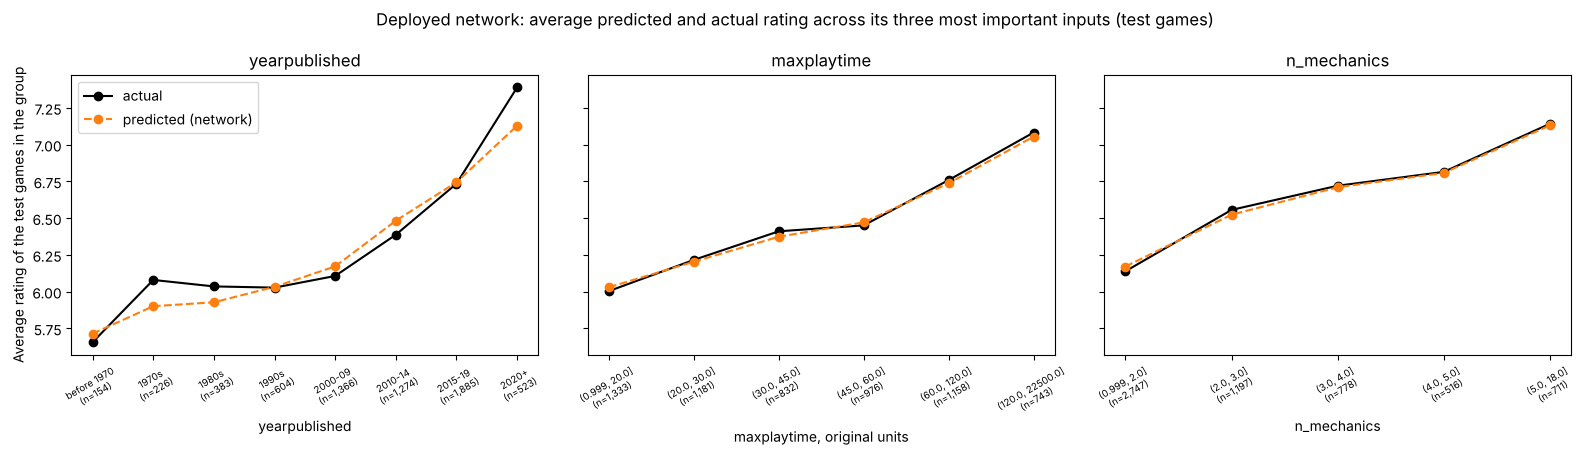

In [16]:
# [AI-assisted] Claude Code, 2026-11-11. Average predicted and actual rating across the deployed model's three most important inputs; reviewed and edited by Ansel Weng.
deployed_pred = test_pred[{"tree": "tree", "k-NN": "k-NN", "network": "network, 5-seed average"}[DEPLOY]]
check = test_df.copy()
check["predicted"] = deployed_pred

def groups_for(col):
    # Groups of test games for one input; games with that input missing are left out of its panel.
    if col == "yearpublished":
        return pd.cut(X_test[col], bins=[-np.inf, 1969, 1979, 1989, 1999, 2009, 2014, 2019, np.inf],
                      labels=["before 1970", "1970s", "1980s", "1990s", "2000-09", "2010-14", "2015-19", "2020+"])
    if col in ["minplayers", "maxplayers", "minplaytime", "maxplaytime"]:
        return pd.qcut(10 ** X_test[col], q=6, duplicates="drop")          # back to minutes or players
    if X_test[col].dropna().isin([0, 1]).all():
        return X_test[col].map({0: "no", 1: "yes"})                       # 0/1 mechanic, category or flag column
    return pd.qcut(X_test[col], q=6, duplicates="drop")

top3 = list(rank_order[:3])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
for ax, col in zip(axes, top3):
    g = check.groupby(groups_for(col).values, observed=True)[["average", "predicted"]].mean()
    n = check.groupby(groups_for(col).values, observed=True).size()
    x = np.arange(len(g))
    ax.plot(x, g["average"], "o-", color="black", label="actual")
    ax.plot(x, g["predicted"], "o--", color="tab:orange", label=f"predicted ({DEPLOY})")
    ax.set_xticks(x)
    ax.set_xticklabels([f"{i}\n(n={c:,})" for i, c in zip(g.index.astype(str), n)], fontsize=7, rotation=30)
    ax.set_title(col)
    ax.set_xlabel(col + (", original units" if col in ["minplayers", "maxplayers", "minplaytime", "maxplaytime"] else ""))
axes[0].set_ylabel("Average rating of the test games in the group")
axes[0].legend()
fig.suptitle(f"Deployed {DEPLOY}: average predicted and actual rating across its three most important inputs (test games)")
plt.tight_layout()
save("13_top_inputs_effect.png")
plt.show()

**Takeaway: newer, longer and more complex games are rated higher, and the network follows each pattern on average.** Average rating rises steadily with maximum play time, from about 6.0 for games of 20 minutes or less to 7.1 for games over two hours. It also rises with the number of listed mechanics, from 6.1 (one or two) to 7.1 (six or more). On both, the network's average prediction sits almost on top of the actual average. In plain terms, BoardGameGeek's raters favour longer, heavier games. That describes the hobby's raters, who are mostly enthusiasts, more than the general public.

**Year is where the network is smoother than the data.** Games before 1970 average about 5.7, the 1970s to 2000s about 6.0 to 6.1, and games from 2020 on 7.4. The network draws a smooth rising curve through this. It under-predicts the 1970s and 1980s by about 0.1 to 0.2, over-predicts 2010–14 by 0.1, and **under-predicts games from 2020 on by about 0.25** (7.13 against 7.39). That is the same drift notebook 08 found: ratings of new games keep rising faster than any model trained on older games expects. With logistic activations, the network's output levels off at the edge of its training years, so like the tree it will need retraining every 2 to 3 years.

## 8. Leakage check on the top inputs

Directives §5.3: a top input that makes no sense should be checked for leakage. Every input the deployed model leans on is known before release: year of publication, play time, player counts, minimum age, the publisher's listed mechanics and categories. The one input that could be partly post-release, `mech_list_missing` (an obscure game is less likely to get its mechanics filled in on BoardGameGeek), was flagged by notebook 05. Its importance is printed below.

In [17]:
# [AI-assisted] Claude Code, 2026-11-11. Where the two list flags rank, for each model; reviewed and edited by Ansel Weng.
flag_rank = pd.DataFrame({label: p["rise in RMSE"].rank(ascending=False).astype(int) for label, p in perm.items()}).loc[["mech_list_missing", "cat_list_missing"]]
flag_size = pd.DataFrame({label: p["rise in RMSE"] for label, p in perm.items()}).loc[["mech_list_missing", "cat_list_missing"]]
pd.concat({"rank among 45 inputs": flag_rank, "rise in test RMSE": flag_size.round(4)}, axis=1)

rank among 45 inputs                                \
                                  tree k-NN network (5-seed average)   
mech_list_missing                    9    5                        5   
cat_list_missing                    34   45                       43   

                  rise in test RMSE                                   
                               tree    k-NN network (5-seed average)  
mech_list_missing             0.006  0.0136                   0.0188  
cat_list_missing              0.000  0.0003                   0.0000

**Takeaway: no leakage concern among the top inputs, with one input to watch.** Year, play time, number of mechanics, Roll / Spin and Move and the wargame category are all on the box before release. `mech_list_missing` ranks 5th of 45 for the deployed network (rise in RMSE 0.019, about 12% of year's), more than for the tree (9th, 0.006). Notebook 05 kept the flag because a brand-new game's listing is also incomplete at prediction time. But a missing mechanic list partly marks an obscure game, and obscurity is partly a result of how a game was received. The report should name it as the one input whose timing is debatable, with its size: removing its information costs at most 0.019 RMSE, so it does not carry the model. `cat_list_missing` does nothing in any model.

## 9. Task 3 re-run on the deployed model (check)

Notebook 07 (Andrew) turns the predicted rating into a production decision, with notebook 04's tree on notebook 04's rows. This section re-runs its sections 3 to 6 unchanged in method, with the deployed model and task 1's rows, so the numbers are ready and section 10's paste cell is tested. Everything is notebook 07's:

- **Hit:** actual rating of 7.0 or more. **Flop** (made, not a hit) costs 3; **missed hit** (not made, was a hit) costs 1.
- The cutoff is chosen on **validation rows** (30% of the training games, `random_state=1`) from 6.0 to 8.5 in steps of 0.1, then scored once on the test games next to making every game or none.
- Other cost ratios: 1:3, 1:1, 2:1, 3:1 and 5:1.

The test set now has 6,415 games instead of 5,395, so the total costs are larger than notebook 07's and are compared within this table, not with notebook 07's.

In [18]:
# [AI-assisted] Claude Code, 2026-11-11. Notebook 07's hit line, cost function and validation split, with the deployed model; reviewed and edited by Ansel Weng.
make["network"] = lambda: SeedAverage(seeds=SEEDS)
make_model = make[DEPLOY]                   # notebook 07's MODEL hook

HIT = 7.0

def decision_cost(produce, hit, flop_cost=3, miss_cost=1):     # notebook 07, section 3, unchanged
    produce = np.asarray(produce)
    hit = np.asarray(hit)
    flops = ((produce == 1) & (hit == 0)).sum()
    missed = ((produce == 0) & (hit == 1)).sum()
    return flop_cost * flops + miss_cost * missed

hit_test = np.where(y_test >= HIT, 1, 0)
X_fit, X_valid, y_fit, y_valid = train_test_split(X_train, y_train, test_size=0.3, random_state=1)
hit_valid = np.where(y_valid >= HIT, 1, 0)
pred_valid = make_model().fit(X_fit, y_fit).predict(X_valid)
pred_test = deployed_pred                    # the deployed model, fitted on all training games in section 5

cutoff_grid = np.round(np.arange(6.0, 8.51, 0.1), 1)
costs = [decision_cost(np.where(pred_valid >= c, 1, 0), hit_valid) for c in cutoff_grid]
best_cut = cutoff_grid[int(np.argmin(costs))]
print("share of hits: validation rows", round(hit_valid.mean(), 3), "| test games", round(hit_test.mean(), 3))
print(f"deployed {DEPLOY}: lowest validation cost {min(costs)} at cutoff {best_cut} (notebook 07's tree on notebook 04's rows: 7.3)")

share of hits: validation rows 0.267 | test games 0.27
deployed network: lowest validation cost 1038 at cutoff 7.4 (notebook 07's tree on notebook 04's rows: 7.3)


In [19]:
# [AI-assisted] Claude Code, 2026-11-11. Notebook 07's policy comparison on the test games, with the deployed model; reviewed and edited by Ansel Weng.
policies = {f"Model, cutoff {best_cut} (chosen)": np.where(pred_test >= best_cut, 1, 0),
            f"Model, naive cutoff {HIT}": np.where(pred_test >= HIT, 1, 0),
            "Make every game": np.ones(len(hit_test), dtype=int),
            "Make no game": np.zeros(len(hit_test), dtype=int)}
rows = []
for name, produce in policies.items():
    rows.append({"policy": name, "total cost": decision_cost(produce, hit_test), "games made": int(produce.sum()),
                 "flops made": int(((produce == 1) & (hit_test == 0)).sum()), "hits missed": int(((produce == 0) & (hit_test == 1)).sum()),
                 "precision": precision_score(hit_test, produce, zero_division=0), "recall": recall_score(hit_test, produce)})
policy_table = pd.DataFrame(rows).set_index("policy").sort_values("total cost")
policy_table.round(3)

,total cost,games made,flops made,hits missed,precision,recall
policy,,,,,,
"Model, cutoff 7.4 (chosen)",1493,477,60,1313,0.874,0.241
Make no game,1730,0,0,1730,0.000,0.000
"Model, naive cutoff 7.0",1835,1247,338,821,0.729,0.525
Make every game,14055,6415,4685,0,0.270,1.000


In [20]:
# [AI-assisted] Claude Code, 2026-11-11. Notebook 07's cost-ratio sensitivity, with the deployed model; reviewed and edited by Ansel Weng.
rows = []
for flop_cost, miss_cost in [(1, 3), (1, 1), (2, 1), (3, 1), (5, 1)]:
    costs_r = [decision_cost(np.where(pred_valid >= c, 1, 0), hit_valid, flop_cost, miss_cost) for c in cutoff_grid]
    cut_r = cutoff_grid[int(np.argmin(costs_r))]
    model_cost = decision_cost(np.where(pred_test >= cut_r, 1, 0), hit_test, flop_cost, miss_cost)
    all_cost = decision_cost(policies["Make every game"], hit_test, flop_cost, miss_cost)
    none_cost = decision_cost(policies["Make no game"], hit_test, flop_cost, miss_cost)
    rows.append({"flop : missed hit": f"{flop_cost} : {miss_cost}", "chosen cutoff": cut_r, "model": model_cost,
                 "make every game": all_cost, "make no game": none_cost,
                 "model saves vs best no-model policy": 1 - model_cost / min(all_cost, none_cost)})
pd.DataFrame(rows).set_index("flop : missed hit").round(3)

,chosen cutoff,model,make every game,make no game,model saves vs best no-model policy
flop : missed hit,,,,,
1 : 3,6.5,2171,4685,5190,0.537
1 : 1,6.9,1146,4685,1730,0.338
2 : 1,7.1,1419,9370,1730,0.180
3 : 1,7.4,1493,14055,1730,0.137
5 : 1,7.5,1587,23425,1730,0.083


**Takeaway: with the deployed network, task 3's decision improves.** At notebook 07's 3:1 costs, the cutoff chosen on the validation rows is **7.4** (notebook 07 had 7.3 with notebook 04's tree; the first run of this notebook, with the tree, had 7.5). On the 6,415 test games, the model costs **1,493**, against 1,730 for making no game and 14,055 for making every game, a **14% saving** over the best no-model policy (the tree saved 9% on the same games: cost 1,570). It makes 477 games, of which 87% are hits, and finds 24% of the hits (the tree found 18%). The naive cutoff of 7.0 (cost 1,835) is again worse than making nothing.

Across cost ratios, the chosen cutoff rises from 6.5 (missing a hit costs 3 times a flop) to 7.5 (a flop costs 5 times a miss). The model beats both no-model policies at every ratio, by 54% down to 8% (the tree: 53% down to 5%). The network's small RMSE gain becomes a clearer gain in the decision, because it ranks the likely hits better near the top of the scale, where the cutoff sits. Notebook 07 will reproduce these numbers once section 10's cell is pasted.

## 10. The cell for notebook 07

Notebook 07 marks two cells to replace: **ROWS** (its section 1 and 2 cells: rows, split and `build_inputs`) and **MODEL** (`make_model()`). The cell below replaces both. In notebook 07, keep the two loading lines at the top of cell 5 (`BASE = ...` and `games = ...`), replace the rest of cell 5, all of cell 6 and all of cell 8 with this one cell, and leave everything else as it is. It is run here and checked against this notebook's rows, inputs and predictions.

Five notes for notebook 07 once it is pasted:

1. **Inputs now have gaps** (the median imputer fills them inside the model's pipeline). Notebook 07's section 7 classifier is fitted on `X_train` directly. scikit-learn's trees accept missing values, so it will run, but ground rule 5 asks for the imputer inside the pipeline: `Pipeline([("impute", SimpleImputer(strategy="median")), ("model", DecisionTreeClassifier(...))])`, with `model__` in front of the grid's keys.
2. **Some test games have no category list.** In section 8, `check["boardgamecategory"].str.contains("Wargame")` returns a missing value for them, which `np.where` counts as a wargame; add `na=False`.
3. The test set grows from 5,395 to 6,415 games, so total costs are not comparable with the earlier run.
4. **The model is now five networks.** Fitting it takes 1 to 3 minutes, and notebook 07 fits it twice (on the fitting rows for the cutoff, and on all training rows). `ConvergenceWarning` can be silenced as in notebook 06. The classifier in notebook 07's section 7 stays a tree: it is task 3's separate try at predicting the category directly.
5. Notebook 07's titles and labels that say "Regression tree" should now say "neural network (5-seed average)".

In [21]:
# [AI-assisted] Claude Code, 2026-11-11. Copy-paste cell for notebook 07, checked against this notebook; reviewed and edited by Ansel Weng.
saved = (X_train.copy(), X_test.copy(), test_df["id"].copy())

# ---- paste into notebook 07 from here: ROWS and MODEL, as settled by tasks 1 and 10 (notebooks 05 and 13) ----
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# ROWS: task 1's rows, split and inputs (notebook 05, section 13)
numeric_cols = ["yearpublished", "minplayers", "maxplayers", "minplaytime", "maxplaytime", "minage", "n_mechanics", "n_categories"]
gaps = games[numeric_cols].isna().sum(axis=1)
data = games[games["yearpublished"].notna() & (gaps < 4)].copy()           # drop no-year games and games missing 4+ of the 8 inputs
data["complete"] = data[numeric_cols].notna().all(axis=1)
tr_c, te_c = train_test_split(data[data["complete"]].reset_index(drop=True), test_size=0.3, random_state=1)    # = notebook 04's split
tr_i, te_i = train_test_split(data[~data["complete"]].reset_index(drop=True), test_size=0.3, random_state=1)
train_df, test_df = pd.concat([tr_c, tr_i], ignore_index=True), pd.concat([te_c, te_i], ignore_index=True)
y_train, y_test = train_df["average"], test_df["average"]

top_mech = train_df["boardgamemechanic"].str.get_dummies(sep="|").mean().sort_values(ascending=False).head(20).index
top_cat = train_df["boardgamecategory"].str.get_dummies(sep="|").mean().sort_values(ascending=False).head(15).index

def build_inputs(frame):
    X = frame[numeric_cols].copy()
    for col in ["minplayers", "maxplayers", "minplaytime", "maxplaytime"]:
        X[col] = np.log10(X[col])
    mech = frame["boardgamemechanic"].str.get_dummies(sep="|").reindex(columns=top_mech, fill_value=0).add_prefix("mech_")
    cat = frame["boardgamecategory"].str.get_dummies(sep="|").reindex(columns=top_cat, fill_value=0).add_prefix("cat_")
    flags = pd.DataFrame({"mech_list_missing": frame["boardgamemechanic"].isna().astype(int),
                          "cat_list_missing": frame["boardgamecategory"].isna().astype(int)}, index=frame.index)
    return pd.concat([X, mech, cat, flags], axis=1)

X_train = build_inputs(train_df)
X_test = build_inputs(test_df)
print("games used:", len(data), "| training rows:", len(train_df), "| test rows:", len(test_df), "| inputs:", X_train.shape[1])

# MODEL: task 10's deployed model (notebook 13): notebook 06's network, fitted with seeds 1 to 5, predictions averaged
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import MinMaxScaler
from sklearn.neural_network import MLPRegressor

def make_network(seed):          # notebook 06: median imputer, MinMax scaling, (2, 2, 2) logistic, rating scaled to 0-1
    net = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", MinMaxScaler()),
                    ("model", MLPRegressor(hidden_layer_sizes=(2, 2, 2), activation="logistic", solver="lbfgs",
                                           tol=1e-8, max_iter=2000, random_state=seed))])
    return TransformedTargetRegressor(regressor=net, func=lambda r: (np.asarray(r) - 1) / 9,
                                      inverse_func=lambda s: np.asarray(s) * 9 + 1, check_inverse=False)

class SeedAverage(RegressorMixin, BaseEstimator):
    """The network fitted once per seed; predicts the average of the seeds' predictions."""
    def __init__(self, seeds=(1, 2, 3, 4, 5)):
        self.seeds = seeds

    def fit(self, X, y):
        self.networks_ = [make_network(seed).fit(X, y) for seed in self.seeds]
        return self

    def predict(self, X):
        return np.mean([net.predict(X) for net in self.networks_], axis=0)

def make_model():
    return SeedAverage(seeds=(1, 2, 3, 4, 5))
# ---- paste to here ----

assert DEPLOY == "network", "the deploy decision changed: update the MODEL part of this cell"
assert X_train.equals(saved[0]) and X_test.equals(saved[1]) and test_df["id"].equals(saved[2])
assert np.allclose(make_model().fit(X_train, y_train).predict(X_test), deployed_pred)
print("the pasted cell rebuilds this notebook's rows, inputs and deployed model's predictions exactly")

games used: 21379 | training rows: 14964 | test rows: 6415 | inputs: 45


the pasted cell rebuilds this notebook's rows, inputs and deployed model's predictions exactly


## 11. What did not work, and notes

- **The first run deployed the tree; the rule was changed after it.** With the network scored by notebook 06's single-seed mean (0.6929), it was 0.0049 ahead of the tree, inside the 0.005 margin, and the tree won as the simpler tied model. Ansel Weng changed decision 4 to score the 5-seed average, the form that is deployed (0.6826, 0.015 ahead). The change was made after seeing the CV numbers but before the test rows were used to choose anything; the test rows agree with both runs' CV ordering. The report should say so plainly.
- **Averaging five networks helped more than any single setting change in notebook 06.** It improved CV by 0.010 and test by 0.008 over one seed, and it removes the seed-to-seed spread (sd 0.0096) that made a single network hard to tell apart from the tree.
- **No method breaks away from the others.** The tree, the network and k-NN are within 0.04 RMSE of each other, and their predictions correlate at 0.76 to 0.90. All three compress the rating scale. The limit is the inputs, not the method.
- **k-NN came last of the three** on every test set. Its distance uses every input equally, so the many weak 0/1 columns dilute the few strong inputs.
- **Seed 3 of the network hit the 2,000-step limit** in its final fit, as in notebook 06. Its single-seed test score (0.697) is within the spread, so it was kept in the average.
- **The deployed model is slower and harder to explain.** Five networks take 1 to 3 minutes to fit, against under a second for the tree, and none of them gives readable rules. Permutation importance and section 7's effect chart stand in for the tree's rules.
- **Runtime.** About 13 minutes on 4 cores, mostly the network: 50 cross-validation fits, 5 final fits, 5 more for task 3's validation rows, and permutation importance. Colab's 2 cores take roughly twice as long.
- **Permutation importance was measured on the test games, after the model was chosen.** It explains the model and is not used to choose anything.

Reading this notebook:

- One split is used throughout, notebook 05's (complete games split as notebook 04, games with a gap split the same way).
- Every number labelled "CV" comes from `KFold(n_splits=5, shuffle=True, random_state=0)` on training games only, the folds notebooks 05 and 06 used. Every number labelled "test" comes from scoring once.
- Every imputer and scaler sits inside a `Pipeline` and is fitted on training rows only.
- Figures are saved to `figures/` with the prefix `13_`.

### Post for the group chat

> **Task 10 is in: deploy the neural network, as the average of 5 seeds** (`notebooks/13_final_comparison_ansel.ipynb`).
>
> **Same footing:** task 1's rows, split and inputs (14,964 training / 6,415 test games, 45 inputs, median imputer), the same 5 CV folds, settings from notebooks 05 and 06, nothing re-tuned. **CV RMSE:** network 0.683 (5-seed average), tree 0.698, k-NN 0.728, linear regression 0.746, baseline 0.922. **Test, all 6,415 games:** network 0.692 (MAE 0.522, R² 0.443), tree 0.702, k-NN 0.730, baseline 0.927.
>
> **Why the network:** scored as it would be deployed (the average of seeds 1 to 5), it beats the tree by 0.015 in CV, three times our 0.005 tie margin. (Scored as one seed, as in notebook 06, it was only 0.005 ahead and tied with the tree; the notebook records that first run.) Cost: five models, slower to fit, no readable rules.
>
> **What drives it:** year of publication by far (shuffling it raises test RMSE by 0.16), then maximum play time, number of mechanics, Roll / Spin and Move (lowers ratings) and a missing mechanic list. The tree relies on the same inputs. Newer, longer and more complex games are rated higher; games from 2020 on are under-predicted by about 0.25, notebook 08's drift.
>
> **@Andrew, task 3:** paste section 10's cell in place of notebook 07's ROWS and MODEL cells (cell 5 after its loading lines, 6 and 8). With it, the 3:1 cutoff becomes 7.4, and the model costs 1,493 against 1,730 for making nothing (a 14% saving; the tree saved 9%). Five small notes are listed above the cell.